# qdebug quickstart: logic bugs vs. noise on the IonQ simulator

Records a *golden* behaviour + noise baseline for a circuit, then classifies later
edits as **PASS / REFACTOR_OK / LOGIC_BUG / NOISE_REGRESSION**.

Run top to bottom. With no `IONQ_API_KEY` it uses the local simulator; with a key
it runs on IonQ's cloud simulator (ideal + hardware noise model).

This effort is supported by Qollab & IonQ.

In [1]:
# 1) Install (skip what your environment already has)
%pip install -q qiskit qiskit-aer qiskit-ionq matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
# 2) Make the qdebug package importable.
#    Put this notebook inside the repo's notebooks/ folder, or upload the repo
#    next to it, or `%pip install -e /path/to/qdebug_project`.
import sys, os, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import qdebug
print("qdebug", qdebug.__version__)

qdebug 0.1.0


In [4]:
# 3) Pick a backend. Default is local Aer so Run-all needs no account or key.
#    To opt into IonQ, set QDEBUG_BACKEND=ionq in the environment before this cell.
#    Do not paste an API key into the notebook.
BACKEND = os.environ.get("QDEBUG_BACKEND", "local")
backend = qdebug.make_backend(BACKEND, noise_model="forte-1")
print(backend.describe())

{'backend': 'local-aer', 'noise': 'depolarizing', 'p1': 0.0005, 'p2': 0.005, 'readout': 0.0}


In [5]:
# 4) Smoke test: connectivity + bit ordering (expects '01' for X on qubit 0)
from qiskit import QuantumCircuit
from qdebug.circuits import probes
qc = QuantumCircuit(2, name="doctor"); qc.x(0)
pc = probes(qc, ("Z",))
print("ideal:", backend.ideal_probs(pc)[0])
print("noisy:", backend.noisy_counts(pc, 200, seed=1)[0])

ideal: {'01': 1.0}
noisy: {'01': 200}


In [6]:
# 5) Record golden snapshots (1 ideal job + N seeded noisy jobs per circuit)
from qdebug import record
from qdebug.demo_suite import golden_circuits, mutants

snaps = {n: record(n, c, backend, shots=1000, n_seeds=3) for n, c in golden_circuits().items()}
for n, s in snaps.items():
    print(f"{n:8s} noise baseline {s.noise.mean:.4f} +/- {s.noise.std:.4f}")

bell     noise baseline 0.0174 +/- 0.0057
bell_rot noise baseline 0.0214 +/- 0.0083
ghz4     noise baseline 0.0331 +/- 0.0036
qft3     noise baseline 0.0325 +/- 0.0036
grover3  noise baseline 0.0568 +/- 0.0052
bv       noise baseline 0.0538 +/- 0.0025


In [7]:
# 6) Check modified circuits: some harmless, some buggy, one just noisier
from qdebug import check
from qdebug.report import format_report, summary_table

reports, expected = [], {}
for m in mutants():
    r = check(m.name, m.circuit, snaps[m.base], backend)
    reports.append(r); expected[m.name] = m.expected
print(summary_table(reports, expected))

case                   verdict           logic dev  noise dev/budget  naive says  expected        
---------------------  ----------------  ---------  ----------------  ----------  ----------------
ghz4_unchanged         PASS              0          0.031/0.084       ok          PASS            
ghz4_extra_HH          REFACTOR_OK       0          0.031/0.084       ok          REFACTOR_OK     
bv_oracle_reordered    REFACTOR_OK       0          0.047/0.096       ok          REFACTOR_OK     
qft3_dead_angle        REFACTOR_OK       0          0.024/0.084       ok          REFACTOR_OK     
ghz4_cx_flipped        LOGIC_BUG         0.5        0.034/0.084       FAIL        LOGIC_BUG       
ghz4_stray_Z           LOGIC_BUG         1          0.030/0.084       FAIL        LOGIC_BUG       
bv_missing_cx          LOGIC_BUG         1          0.046/0.096       FAIL        LOGIC_BUG       
grover3_wrong_oracle   LOGIC_BUG         0.94       0.056/0.114       FAIL        LOGIC_BUG       
qft3_phase

In [8]:
# 7) Why did one fail? Full explanation + blamed edit
for r in reports:
    if r.name in ("ghz4_cx_flipped", "bell_tiny_phase_drift", "ghz4_cx_padding"):
        print(format_report(r)); print()

[LOGIC_BUG] ghz4_cx_flipped
  ideal (noise-free) output moved by TVD=0.5 in the Z basis (tol 1e-09) - this is a logic change, not noise. Culprit edit(s): hunk 0 ([cx q0,q1] -> [cx q1,q0], effect 0.5)
  logic dev (exact ideal TVD): 0.5  tol 1e-09   |  noise dev: 0.0337  budget: 0.0843   |  naive noisy-vs-golden: 0.5167
  exact check (unitary): state distance 0.866  |  unitary distance 0.968
  @@ golden[1:2] -> modified[1:2] (replace)
    - cx q0,q1
    + cx q1,q0
  blame: hunk 0 effect=0.5  <-- culprit

[LOGIC_BUG] bell_tiny_phase_drift
  ideal (noise-free) output moved by TVD=0.0006249 in the X basis (tol 1e-09) - this is a logic change, not noise. Culprit edit(s): hunk 0 ([-] -> [rz(0.05) q0], effect 0.000625)
  logic dev (exact ideal TVD): 0.000625  tol 1e-09   |  noise dev: 0.0115  budget: 0.0789   |  naive noisy-vs-golden: 0.0117
  exact check (unitary): state distance 0.025  |  unitary distance 0.025
  @@ golden[2:2] -> modified[2:3] (insert)
    + rz(0.05) q0
  blame: hunk 0 effe

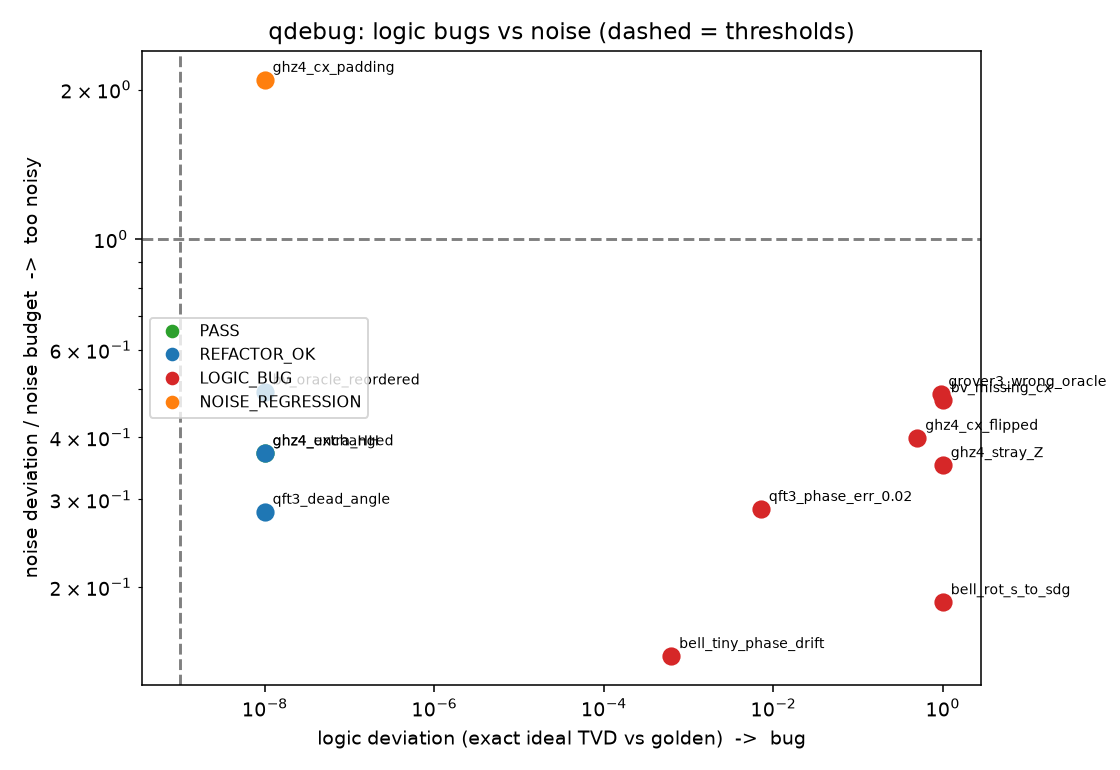

In [9]:
# 8) Logic-vs-noise map
from qdebug.report import plot_reports
from IPython.display import Image, display
png = plot_reports(reports, "qdebug_map.png")
display(Image(png)) if png else print("matplotlib not installed")

## Use it on your own circuit

```python
snap = record("my_circuit", my_golden_circuit, backend)
report = check("my_circuit", my_edited_circuit, snap, backend)
print(format_report(report))
```
Circuits must be unitary (no mid-circuit measurement); measurements are added for you.